# STEP3. EDA

## 분석 질문
- 기초통계 · 시계열 · 상관관계 · 데이터 검증
- STEP4(산업별 금리 베타 분석)에 앞서, 생성한 변수들의 분포와 관계를 확인하고 회귀분석에 사용할 수 있는 데이터인지 점검한다.
- 관련 가설: H1·H2 공통 기반 (EDA)

## 입력
- 입력 파일: `industry_rate_panel_daily.csv`
- 이전 STEP 결과: STEP1(`01_data_preparation.ipynb`) + STEP2(`02_variable_generation.ipynb`)

## 출력
- Figure: `results/EDA/figures/industry_return_timeseries.png`, `kospi_return_timeseries.png`, `interest_rate_timeseries.png`, `termspread_timeseries.png`, `correlation_heatmap.png`
- Table: `results/EDA/tables/descriptive_statistics.csv`, `descriptive_statistics_by_industry.csv`, `correlation_matrix.csv`
- Summary: `results/EDA/summary.md`

## 주요 변수
- industry_return : 산업별 일별 수익률
- kospi_return : KOSPI 일별 수익률
- d_y3 : 국고채 3년 금리 변화분
- d_y10 : 국고채 10년 금리 변화분
- term_spread : 장단기 금리차(10Y-3Y)
- d_term_spread : 장단기 금리차 변화분

## 분석 시 주의사항
- 수익률은 소수(fraction) 단위, 금리 변화는 %p 단위이다.
- d_term_spread = d_y10 - d_y3 관계가 있어 STEP4에서 세 변수를 동시에 쓰지 않는다.

## 준비 및 데이터 불러오기
### 목적
- 라이브러리·한글 폰트를 설정하고 패널 데이터를 불러와 정렬한다.

In [ ]:
# [셀 1] 라이브러리 · 한글폰트 · 경로
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.font_manager as fm
import seaborn as sns

# 저장소 루트를 찾아 config를 불러온다 (실행 위치/편집기와 무관하게 동작).
# 저장소 루트에서 `pip install -e .` 를 한 번 실행했다면 아래 탐색은 건너뛴다.
import sys
from pathlib import Path

_anchors = []
if "__vsc_ipynb_file__" in globals():          # VS Code Notebook
    _anchors.append(Path(globals()["__vsc_ipynb_file__"]).resolve().parent)
if globals().get("_dh"):                        # IPython 커널 시작 폴더 (Jupyter/Lab/Colab)
    _anchors.append(Path(globals()["_dh"][0]).resolve())
_anchors.append(Path.cwd().resolve())           # 최후 수단

# config.py 와 requirements.txt 를 '둘 다' 가진 폴더만 저장소 루트로 인정한다.
# 마커를 하나만 보면 다른 폴더의 동명 config.py 를 잘못 집을 수 있다.
_root = next(
    (p for a in _anchors for p in [a, *a.parents]
     if (p / "config.py").is_file() and (p / "requirements.txt").is_file()),
    None,
)
# 이미 sys.path에 있더라도 맨 앞으로 올린다. cwd(예: 바탕화면)가 앞에 있으면
# 같은 이름의 다른 config.py 가 먼저 잡히기 때문이다.
if _root is not None:
    if str(_root) in sys.path:
        sys.path.remove(str(_root))
    sys.path.insert(0, str(_root))

import config

if _root is not None and Path(config.__file__).resolve().parent != _root:
    raise ImportError(
        f"의도하지 않은 config.py 가 import 되었습니다: {config.__file__}\n"
        f"저장소 루트({_root})에서 `pip install -e .` 를 실행하세요."
    )


PANEL_CSV = config.PROCESSED_DIR / "industry_rate_panel_daily.csv"   # 00 -> 01에서 저장한 최종 데이터
FIGDIR = str(config.FIGDIR); TABDIR = str(config.TABDIR)
os.makedirs(FIGDIR, exist_ok=True); os.makedirs(TABDIR, exist_ok=True)

# 한글 폰트 (환경별 후보)
for fp in ["/usr/share/fonts/truetype/nanum/NanumGothic.ttf",
           "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
           "C:/Windows/Fonts/malgun.ttf", "/Library/Fonts/AppleGothic.ttf"]:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp); plt.rcParams["font.family"] = fm.FontProperties(fname=fp).get_name(); break
else:
    for c in ["Malgun Gothic","AppleGothic","NanumGothic"]:
        if any(c in f.name for f in fm.fontManager.ttflist): plt.rcParams["font.family"]=c; break
plt.rcParams["axes.unicode_minus"] = False

VARS = ["industry_return","kospi_return","d_y3","d_y10","term_spread","d_term_spread"]
UNIT = {"industry_return":"소수","kospi_return":"소수","d_y3":"%p","d_y10":"%p","term_spread":"%p","d_term_spread":"%p"}

In [2]:
# [셀 2] 데이터 로드 · 정렬
df = pd.read_csv(PANEL_CSV, encoding="utf-8-sig")
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["industry","date"]).reset_index(drop=True)
industries = sorted(df["industry"].unique())
daily = df.drop_duplicates("date").sort_values("date").reset_index(drop=True)  # 날짜당 1행(KOSPI·금리)
print(df.shape, "| 산업", len(industries), "| 거래일", daily.shape[0])

(17164, 12) | 산업 7 | 거래일 2452


## 기초통계
### 목적
- 변수의 분포와 데이터 상태를 확인한다.

In [3]:
# [셀 3] 기초통계 (평균/표준편차/최소/최대/중앙/결측)
def describe(s):
    return pd.Series({"mean":s.mean(),"std":s.std(),"min":s.min(),"max":s.max(),
                      "median":s.median(),"n_missing":s.isna().sum()})
rows = {"industry_return": describe(df["industry_return"])}
for v in ["kospi_return","d_y3","d_y10","term_spread","d_term_spread"]:
    rows[v] = describe(daily[v])
stats = pd.DataFrame(rows).T; stats["unit"] = [UNIT[v] for v in stats.index]; stats.index.name="variable"
stats.to_csv(f"{TABDIR}/descriptive_statistics.csv", encoding="utf-8-sig")

by_ind = df.groupby("industry")["industry_return"].apply(describe).unstack().reindex(industries)
by_ind.index.name="industry"
by_ind.to_csv(f"{TABDIR}/descriptive_statistics_by_industry.csv", encoding="utf-8-sig")
display(stats.round(6)); display(by_ind.round(6))

,mean,std,min,max,median,n_missing,unit
variable,,,,,,,
industry_return,0.000386,0.016382,-0.133038,0.147541,0.000145,7.0,소수
kospi_return,0.000383,0.011111,-0.087677,0.086012,0.000699,1.0,소수
d_y3,0.000538,0.038799,-0.268000,0.349000,0.000000,1.0,%p
d_y10,0.000547,0.041304,-0.196000,0.321000,0.000000,1.0,%p
term_spread,0.322668,0.220517,-0.213000,1.042000,0.326000,0.0,%p
d_term_spread,0.000009,0.021281,-0.163000,0.117000,0.000000,1.0,%p


,mean,std,min,max,median,n_missing
industry,,,,,,
건설업,0.000134,0.017870,-0.118374,0.147541,-0.000159,1.0
금융업,0.000350,0.013031,-0.103676,0.112835,0.000324,1.0
운수장비,0.000543,0.016231,-0.105239,0.125083,0.000155,1.0
의약품,0.000457,0.018051,-0.117294,0.122435,-0.000288,1.0
전기전자,0.000812,0.015792,-0.095694,0.109055,0.000628,1.0
철강금속,0.000405,0.018379,-0.133038,0.126327,0.000033,1.0
화학,-0.000001,0.014600,-0.115122,0.090169,0.000199,1.0


### 관찰 결과 — 기초통계

**변수별 (KOSPI·금리)**
- 평균: 수익률과 금리 변화는 모두 평균이 0에 가까웠다.
- 표준편차: 금리 변화가 KOSPI 수익률보다 더 크게 움직였다.
- 최솟값·최댓값: 장단기 금리차는 다른 변수보다 값의 범위가 더 넓었다.
- 결측값: 첫 거래일만 결측치가 발생했으며 정상적인 결측치였다.

**산업별 수익률**
- 평균: 전기전자의 평균 수익률이 가장 높고, 화학이 가장 낮았다.
- 표준편차: 철강금속·의약품·건설업의 변동성이 크고, 금융업·화학은 상대적으로 작았다.
- 최솟값·최댓값: 산업별로 하루 최대 하락폭과 상승폭에 차이가 나타났다.

→ STEP4: 산업마다 가격이 움직이는 정도가 달라 산업별 금리 민감도를 따로 분석한다.

## 시계열 분석
### 목적
- 시간에 따른 변수의 변화를 확인한다.

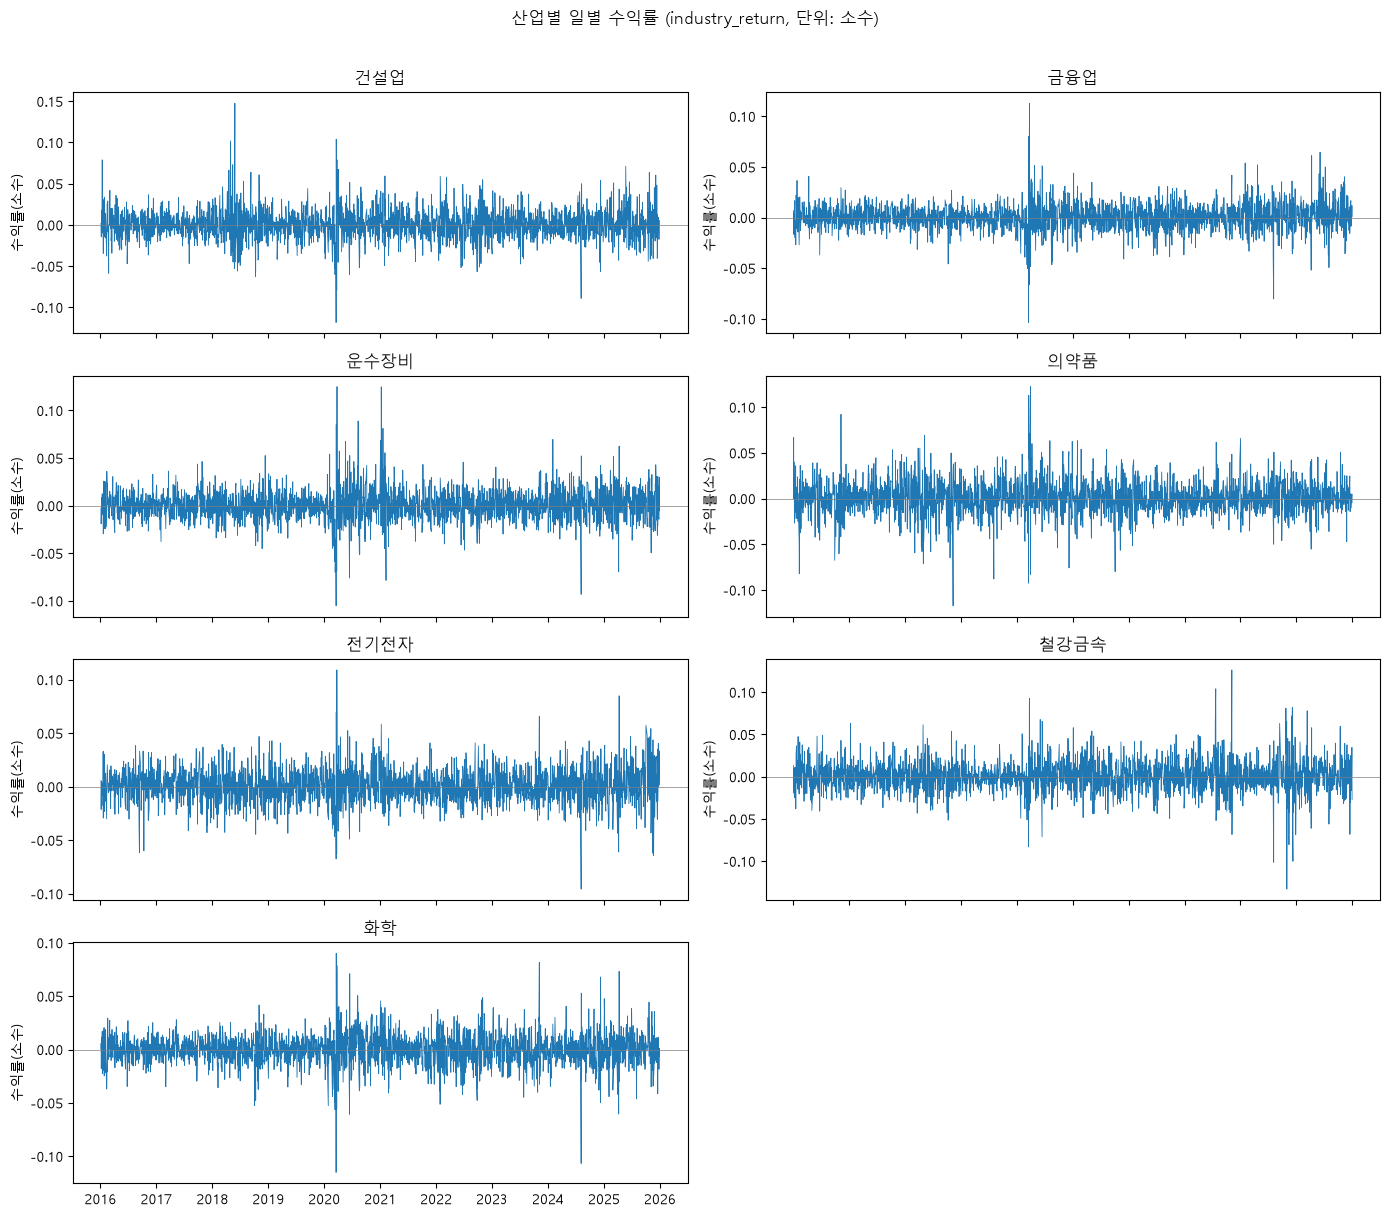

In [4]:
# [셀 4-1] 산업별 수익률 facet
n=len(industries); ncol=2; nrow=int(np.ceil(n/ncol))
fig,axes=plt.subplots(nrow,ncol,figsize=(14,3.0*nrow),sharex=True); axes=axes.flatten()
for i,ind in enumerate(industries):
    sub=df[df["industry"]==ind]
    axes[i].plot(sub["date"],sub["industry_return"],lw=0.6); axes[i].axhline(0,color="grey",lw=0.5)
    axes[i].set_title(ind); axes[i].set_ylabel("수익률(소수)")
for j in range(n,len(axes)): axes[j].axis("off")
fig.suptitle("산업별 일별 수익률 (industry_return, 단위: 소수)",y=1.01)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/industry_return_timeseries.png",dpi=130,bbox_inches="tight"); plt.show()

### 관찰 결과 — 산업별 일별 수익률
- 7개 산업 모두 0을 중심으로 위아래로 움직인다.
- 움직이는 폭은 산업마다 다르다(철강금속·의약품·건설업이 크게 움직임).
- 2020년 초에는 모든 산업이 동시에 크게 흔들린다.
- 평균이 가장 높은 산업은 전기전자, 가장 낮은 산업은 화학이다.

→ STEP4: 산업을 나눠 회귀할 근거가 된다. 2020년 같은 공통 충격은 시장 변수(KOSPI)로 걸러낸다.

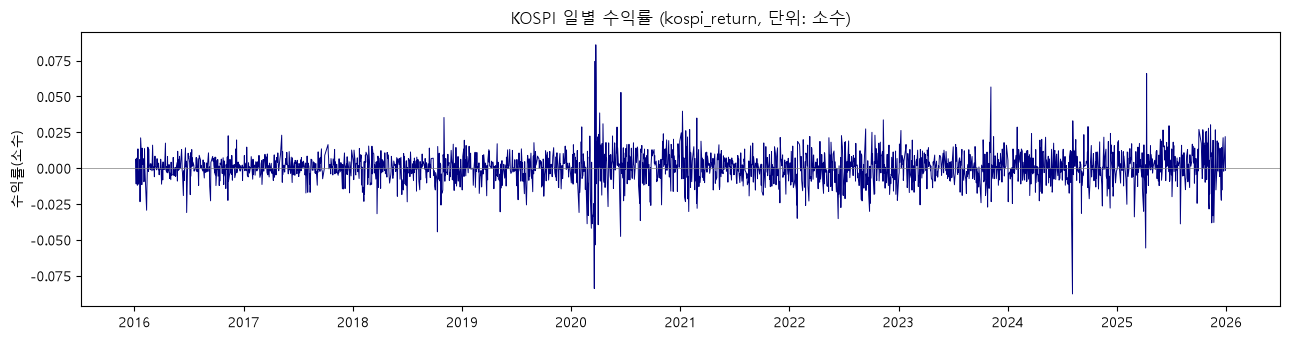

In [5]:
# [셀 4-2] KOSPI 수익률
fig,ax=plt.subplots(figsize=(13,3.5))
ax.plot(daily["date"],daily["kospi_return"],lw=0.7,color="navy"); ax.axhline(0,color="grey",lw=0.5)
ax.set_title("KOSPI 일별 수익률 (kospi_return, 단위: 소수)"); ax.set_ylabel("수익률(소수)")
fig.tight_layout(); fig.savefig(f"{FIGDIR}/kospi_return_timeseries.png",dpi=130,bbox_inches="tight"); plt.show()

### 관찰 결과 — KOSPI 일별 수익률
- 평소에는 좁은 폭으로 움직인다(표준편차 0.011로 개별 산업보다 작다).
- 2020년 초에 크게 떨어졌다가 회복하는 큰 움직임이 있다.

→ STEP4: 시장 전체 움직임을 통제 변수로 넣어, 금리 효과만 따로 본다.

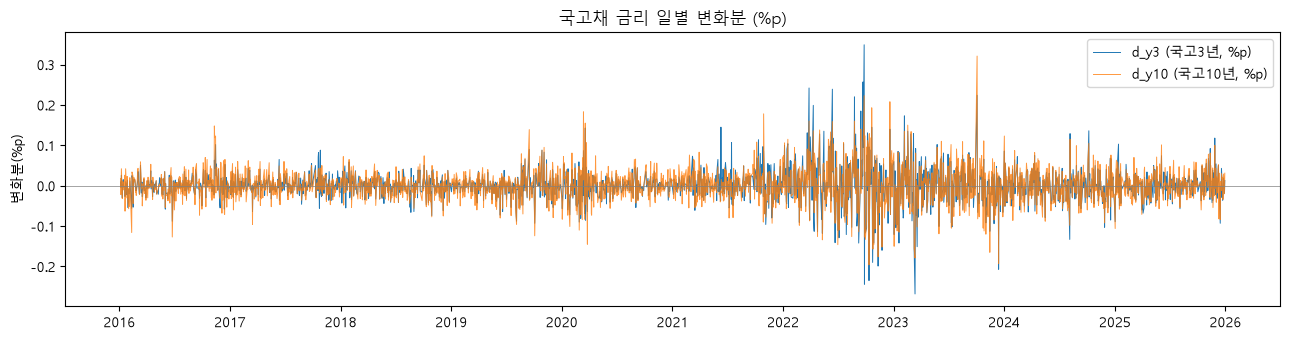

In [6]:
# [셀 4-3] d_y3 & d_y10
fig,ax=plt.subplots(figsize=(13,3.5))
ax.plot(daily["date"],daily["d_y3"],lw=0.7,label="d_y3 (국고3년, %p)")
ax.plot(daily["date"],daily["d_y10"],lw=0.7,label="d_y10 (국고10년, %p)",alpha=0.8)
ax.axhline(0,color="grey",lw=0.5); ax.set_title("국고채 금리 일별 변화분 (%p)"); ax.set_ylabel("변화분(%p)"); ax.legend()
fig.tight_layout(); fig.savefig(f"{FIGDIR}/interest_rate_timeseries.png",dpi=130,bbox_inches="tight"); plt.show()

### 관찰 결과 — 금리 변화(d_y3·d_y10)
- 3년물과 10년물이 대부분 같은 방향으로 움직인다(상관 0.86).
- 10년물이 3년물보다 조금 더 크게 움직인다(표준편차 0.041 vs 0.039).
- 2022년 앞뒤로 하루 변동 폭이 더 커진다.

→ STEP4: 두 금리가 겹쳐 움직이므로 함께 넣으면 정보가 중복된다. 사양을 나눠야 한다.

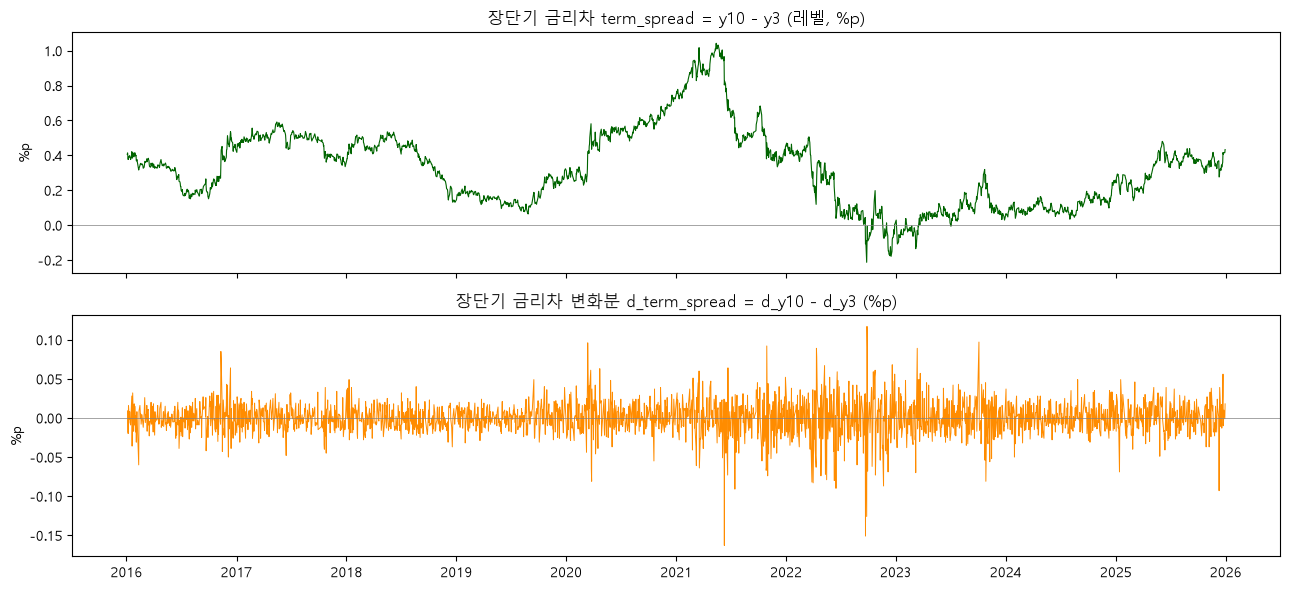

In [7]:
# [셀 4-4] term_spread & d_term_spread (레벨 vs 변화분)
fig,(a1,a2)=plt.subplots(2,1,figsize=(13,6),sharex=True)
a1.plot(daily["date"],daily["term_spread"],lw=0.8,color="darkgreen"); a1.axhline(0,color="grey",lw=0.5)
a1.set_title("장단기 금리차 term_spread = y10 - y3 (레벨, %p)"); a1.set_ylabel("%p")
a2.plot(daily["date"],daily["d_term_spread"],lw=0.7,color="darkorange"); a2.axhline(0,color="grey",lw=0.5)
a2.set_title("장단기 금리차 변화분 d_term_spread = d_y10 - d_y3 (%p)"); a2.set_ylabel("%p")
fig.tight_layout(); fig.savefig(f"{FIGDIR}/termspread_timeseries.png",dpi=130,bbox_inches="tight"); plt.show()

### 관찰 결과 — 장단기 금리차
- 금리차(레벨, term_spread)는 시기마다 오르내린다(평균 0.32, 최저 -0.21 ~ 최고 1.04 %p).
- 금리차의 하루 변화(d_term_spread)는 0을 중심으로 좁게 움직인다.

→ STEP4: 회귀에는 레벨보다 하루 변화값(d_term_spread)이 적합하다.

## 상관관계 분석
### 목적
- 변수 간 관계를 확인한다.

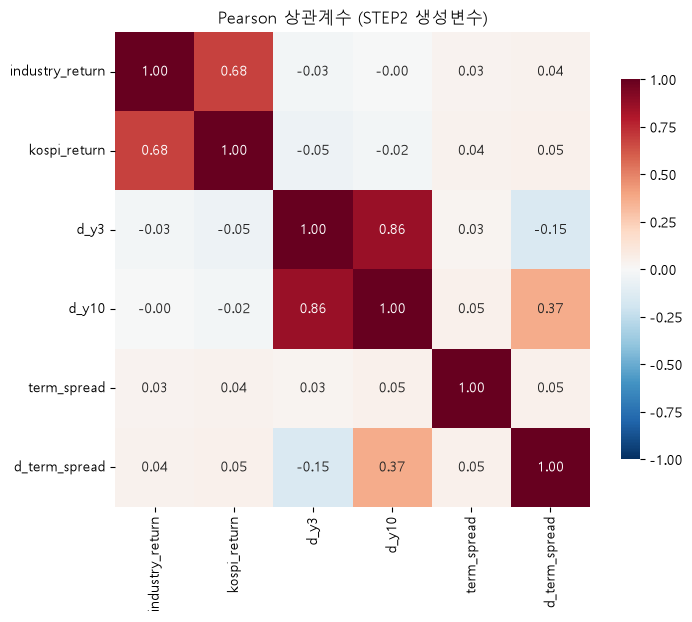

,industry_return,kospi_return,d_y3,d_y10,term_spread,d_term_spread
industry_return,1.000,0.680,-0.028,-0.005,0.033,0.041
kospi_return,0.680,1.000,-0.054,-0.025,0.042,0.051
d_y3,-0.028,-0.054,1.000,0.861,0.029,-0.153
d_y10,-0.005,-0.025,0.861,1.000,0.053,0.372
term_spread,0.033,0.042,0.029,0.053,1.000,0.048
d_term_spread,0.041,0.051,-0.153,0.372,0.048,1.000


In [8]:
# [셀 5] Pearson 상관계수 + Heatmap
corr = df[VARS].corr(method="pearson"); corr.to_csv(f"{TABDIR}/correlation_matrix.csv", encoding="utf-8-sig")
fig,ax=plt.subplots(figsize=(7.5,6.2))
sns.heatmap(corr,annot=True,fmt=".2f",cmap="RdBu_r",vmin=-1,vmax=1,square=True,cbar_kws={"shrink":0.8},ax=ax)
ax.set_title("Pearson 상관계수 (STEP2 생성변수)")
fig.tight_layout(); fig.savefig(f"{FIGDIR}/correlation_heatmap.png",dpi=130,bbox_inches="tight"); plt.show()
display(corr.round(3))

### 관찰 결과 — 상관관계
- 산업 수익률과 KOSPI 수익률의 상관이 0.68로 높다(같이 움직임).
- d_y3와 d_y10의 상관이 0.86으로 매우 높다(정보가 겹침).
- d_term_spread는 d_y10과 0.37, d_y3과 -0.15로, 두 금리 변화의 조합임이 드러난다.
- 금리 변수와 수익률의 직접 상관은 |0.05| 이하로 약하다.

→ STEP4: 시장 변수(KOSPI)를 통제하고, 금리 변수끼리 중복을 피해 사양을 나눈다.

## 데이터 검증
### 목적
- 회귀분석 전에 데이터를 점검한다.

In [9]:
# [셀 6] 데이터 검증
chk={}
chk["date_dtype"]=str(df["date"].dtype)
chk["sorted_within_industry"]=bool(df.groupby("industry")["date"].apply(lambda s:s.is_monotonic_increasing).all())
chk["dup_date_industry"]=int(df.duplicated(["date","industry"]).sum())
chk["balanced_panel"]=bool(df["industry"].value_counts().nunique()==1)
chk["missing"]=df[VARS].isna().sum().to_dict()
chk["ir_missing_beyond_first_day"]=int(df[df["date"]!=df["date"].min()]["industry_return"].isna().sum())
chk["identity_d_term_spread_err"]=float((df["d_term_spread"]-(df["d_y10"]-df["d_y3"])).abs().max())
chk["identity_term_spread_err"]=float((df["term_spread"]-(df["y10"]-df["y3"])).abs().max())
chk["outliers_absz_gt4"]={v:int(((df[v]-df[v].mean())/df[v].std()).abs().gt(4).sum()) for v in VARS}
for k,v in chk.items(): print(k,":",v)

date_dtype : datetime64[us]
sorted_within_industry : True
dup_date_industry : 0
balanced_panel : True
missing : {'industry_return': 7, 'kospi_return': 7, 'd_y3': 7, 'd_y10': 7, 'term_spread': 0, 'd_term_spread': 7}
ir_missing_beyond_first_day : 0
identity_d_term_spread_err : 1.1796119636642288e-16
identity_term_spread_err : 2.220446049250313e-16
outliers_absz_gt4 : {'industry_return': 84, 'kospi_return': 91, 'd_y3': 119, 'd_y10': 77, 'term_spread': 0, 'd_term_spread': 98}


### 관찰 결과 — 데이터 검증
- 날짜 형식·정렬 정상, 같은 날짜·산업이 겹친 행 없음.
- 7개 산업 × 2,452거래일로 개수가 모두 같다(균형패널).
- 빈 값은 각 산업 첫 거래일뿐이고, 계산할 때 자동으로 빠진다.
- d_term_spread = d_y10 − d_y3 항등식이 정확히 맞는다(오차 ≈ 0).

→ STEP4: 따로 정제하지 않아도 회귀에 바로 넣을 수 있다.

## 정리 — STEP4에서 쓸 점
1. **산업별로 나눠서 본다.** 산업마다 변동성이 달라 금리 반응(베타)도 다를 수 있다.
2. **KOSPI를 통제 변수로 넣는다.** 산업 수익률이 시장과 0.68로 같이 움직이므로, 시장 영향을 뺀 뒤 금리 효과를 본다.
3. **금리 변수는 겹치지 않게 넣는다.** d_y3·d_y10·d_term_spread는 정보가 겹친다(d_term_spread = d_y10 − d_y3). 3년+10년, 또는 한쪽 만기+금리차로 나눈다.
4. **금리는 레벨이 아니라 하루 변화값(d_*)을 쓴다.**
5. **단위 차이에 주의한다.** 수익률은 소수, 금리 변화는 %p. 베타는 "금리 1%p 움직일 때 수익률이 얼마 변하나"로 읽는다.

## STEP3 요약

### Takeaway
- 데이터 검증, 기초통계, 시계열, 상관관계 확인을 완료했다.
- 산업별 변동성 차이, 시장 요인과의 동조성, 금리 변수 간 중복 정보를 확인해 STEP4 회귀 설계에 반영할 점을 정리했다.
- 다음 단계: STEP4 산업별 금리 베타 추정.
- STEP4 진행 시 확인: d_y3·d_y10·d_term_spread 동시 투입 금지, KOSPI 통제 변수 포함, 수익률(소수)·금리 변화(%p) 단위 차이 주의.